# 10 · Hazır VQC sınıflandırıcısı

**Amaç:** Elle yazılan eğitim akışını ZZFeatureMap, RealAmplitudes ve SPSA içeren VQC arayüzüyle karşılaştırmak.

**Okuma notu:** Keşif grafikleri 150 gözlemi gösterse de eğitim maskeyle 100 gözlem / iki sınıfa iner. AerEstimator oluşturulur ama VQC nesnesine aktarılmaz: VQC kendi varsayılan sampler yolunu kullanır. Ölçekleyici bölmeden önce fit edildiği için veri sızıntısı vardır.

**Durum:** Staj çalışması arşivi. Aşağıdaki çıktılar ZIP içinde kayıtlı geçmiş çalıştırmalara aittir; bu yayına hazırlık sırasında üretilmiş yeni deney sonuçları değildir. Deney kodu ve eski açıklamalar gelişim sürecini göstermek için korunmuştur; yöntem düzeltmeleri ve sınırlılıklar için [çalışma rehberini](../../docs/CALISMA_REHBERI.md), [sonuçları](../../docs/SONUCLAR.md) ve [yöntem incelemesini](../../docs/YONTEM_VE_SINIRLAR.md) okuyun.

**English:** Historical internship experiment. See the [English overview](../../README_EN.md). Saved outputs are historical evidence, not a fresh reproducibility claim.


Bu Çalışmada VQC Kullanarak iris veri setinde kuantum makine öğrenmesi denemesi yapılmaktadır.

!pip install qiskit
!pip install qiskit-machine-learning
!pip install pylatexenc

#### VQC:

* Hazır bir “classifier” modeli (tıpkı scikit-learn’de SVC gibi).
* İçinde feature map + ansatz + optimizer zaten tanımlıdır.
* Kullanımı kolaydır ama esnekliği kısıtlıdır.

#### QNN:

* Daha genel yapı → “quantum layer” gibi davranır.
* Kendi loss fonksiyonunu, optimizer’ını ve training loop’unu daha esnek şekilde kurmana izin verir.
* PyTorch / TensorFlow ile entegre edilebilir, hybrid modeller yapılabilir.

In [1]:
# Veri setini yükleyelim ve açıklamasını yazdıralım

from sklearn.datasets import load_iris
iris_data = load_iris()
print(iris_data.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

* 150 veri noktası var, 3 sınıf mevcut ve her sınıf için eşit sayıda veri noktası bulunuyor.

* Çiçeklerin çanak yaprakları (sepal) ve taç yapraklarının (petal) boyutlarını tanımlayan dört özellik var.

* Eksik değer yok (imputasyon gerekmez :D).

* Taç yaprak özellikleri arasında yüksek korelasyon var, bu nedenle gerekirse ikisi yerine sadece biri kullanılabilir (boyut indirgeme yapılabilir).

* Taç yaprak uzunluğu için aykırı değerler olabilir (temizlenmesi gerekebilir).

* Ortalamalar büyük ölçüde farklılık gösteriyor (ölçeklendirme yapılması gerekir)

In [2]:
features = iris_data.data
targets = iris_data.target

- features: Iris veri setindeki özellikler (sepal length, sepal width, petal length, petal width), 150x4 boyutlu matris.

- targets: Çiçek türleri (etiketler), 0 = Setosa, 1 = Versicolor, 2 = Virginica.

In [3]:
# Özellikleri [0, 1] aralığına ölçekleyelim

from sklearn.preprocessing import MinMaxScaler
features = MinMaxScaler().fit_transform(features)
# Ölçeklenmiş veriyi features değişkenine atadım

In [4]:
# Verileri pandas DataFrame'e dönüştürelim ve ilk birkaç satırı görüntüleyelim
import pandas as pd
import seaborn as sns

features_df = pd.DataFrame(features, columns=iris_data.feature_names)
features_df["target"] = pd.Series(targets)
print(features_df.head())


   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0           0.222222          0.625000           0.067797          0.041667   
1           0.166667          0.416667           0.067797          0.041667   
2           0.111111          0.500000           0.050847          0.041667   
3           0.083333          0.458333           0.084746          0.041667   
4           0.194444          0.666667           0.067797          0.041667   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  


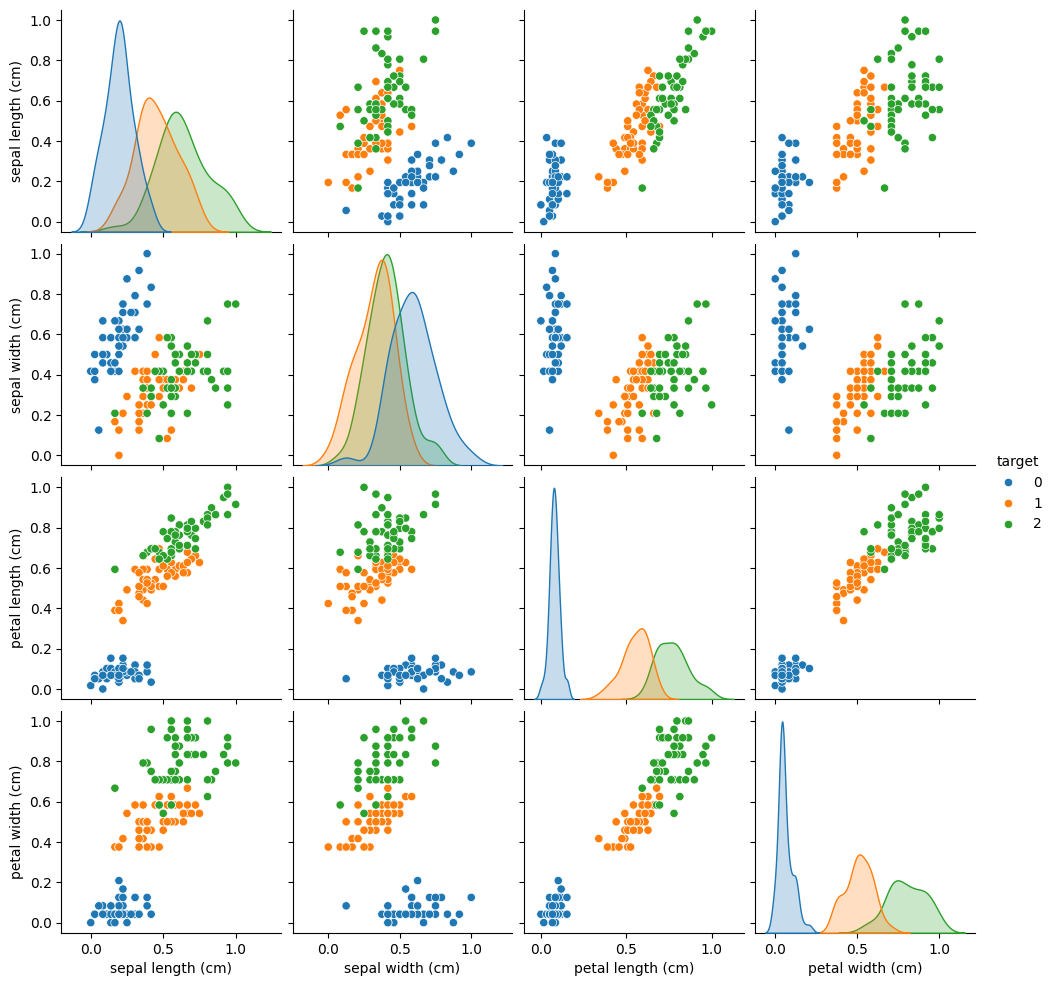

In [5]:
sns.pairplot(features_df, hue='target', palette='tab10')

Mavi çiçekler, turuncu ve yeşil olanlara kıyasla daha kolay ayırt edilebiliyor. Bu, modelin yanlış sınıflandırmalarını incelemek ve hangi hataların yapıldığını görmek istediğimizde not edilmesi gereken faydalı bir durum.

Ayrıca, pozitif korelasyonlar mevcut; örneğin taç yaprak uzunluğu ile genişliği ve çanak yaprak ile taç yaprak uzunluğu arasında.

Şimdi modellemeye geçelim.

Kullanılması en basit modellerden biri variational quantum classifier (VQC)’dir. 

1. Feature map, klasik veriyi kuantum devresine kodlar 
2. Ansatz, ayarlanabilir parametreli kuantum devresidir 
3. Optimizer, bu parametreleri değiştirerek amaç fonksiyonunu minimize eder.

Şimdi sırasıyla bunları yapacağız

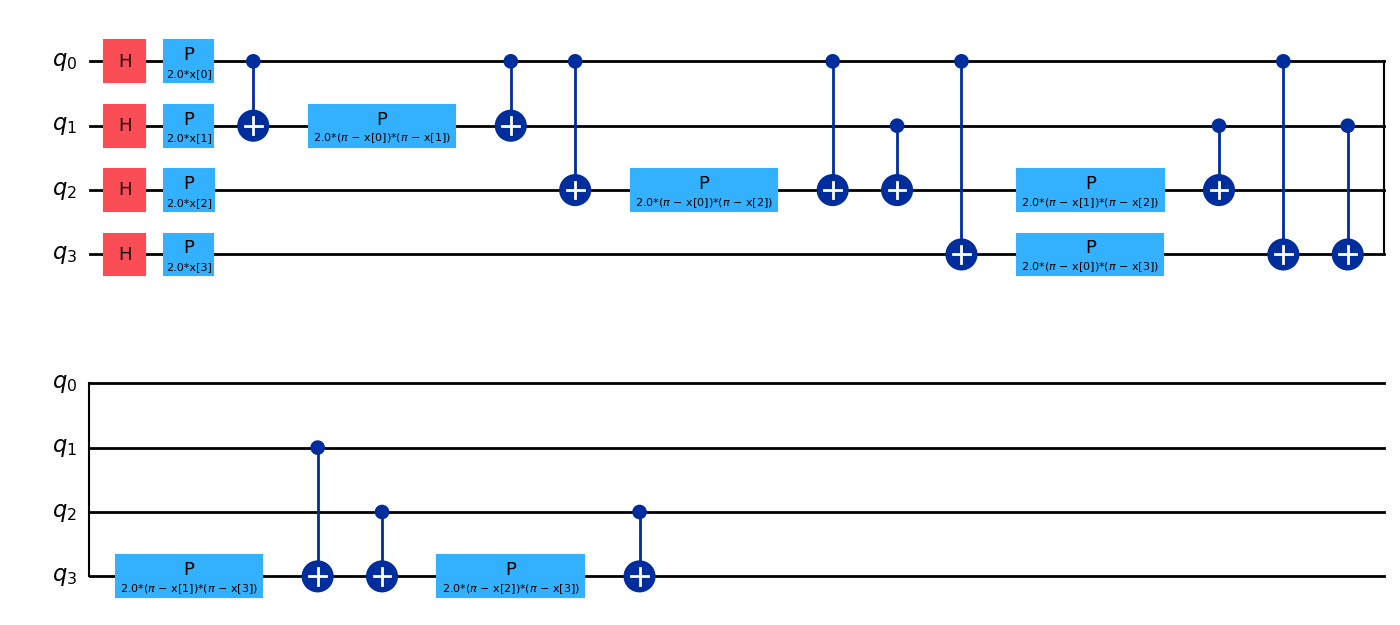

In [6]:
from qiskit.circuit.library import ZZFeatureMap

num_feats = features.shape[1] 
feat_map = ZZFeatureMap(feature_dimension=num_feats, reps=1)
feat_map.decompose().draw('mpl', fold=20)

ZZFeatureMap:

- Her feature için bir kübit açıyor.
- reps=1: feature map tek katman uygulanıyor.
- ZZ etkileşim terimleriyle kübitler arası dolanıklık (entanglement) ekleniyor.

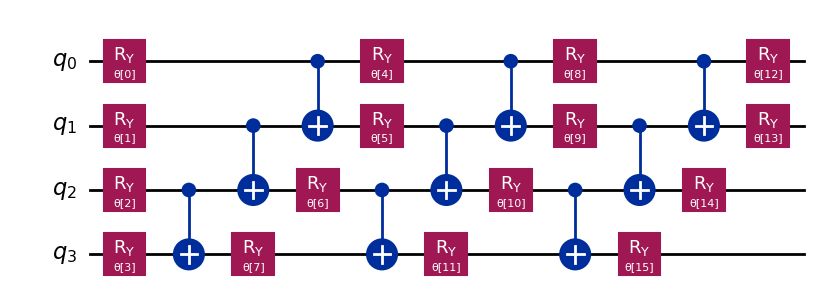

In [7]:
# Ansatz (parametreli kuantum devresi) tanımlayalım

from qiskit.circuit.library import RealAmplitudes
ansatz = RealAmplitudes(num_qubits=num_feats, reps=3)
ansatz.decompose().draw('mpl', fold=20)

Buradaki amacımız train edilebilir parametreler (θ) ile kuantum devresini esnek hale getirmek.

RealAmplitudes:

- Tekli qubit rotasyonları (Ry) ve CX kapıları içerir.
- reps=3: bu yapıyı 3 kez üst üste koyuyor böylece daha güçlü ifade yeteneği elde ediyoruz.

Bu parametreler (θ) klasik optimizer tarafından güncellenerek optimize hale getiriliyor.

θ[0]…θ[15], sınıflandırıcının ağırlıklarıdır; eğitim sırasında optimize edilir.

Bu ağırlıkları güncellemek için bir amaç fonksiyonu (loss) gerekir. Eğitimi hızlandırmak için burada türevsiz (gradient-free) bir yöntem seçilecektir.

In [10]:

import qiskit, qiskit_aer, sklearn, numpy as np
import qiskit_machine_learning
from qiskit_algorithms.utils import algorithm_globals

print("Qiskit:", qiskit.__version__)
print("Aer:", qiskit_aer.__version__)
print("QML:", qiskit_machine_learning.__version__)
print("scikit-learn:", sklearn.__version__)

# Tekrarlanabilirlik için seed
algorithm_globals.random_seed = 42
np.random.seed(42)


Qiskit: 1.2.4
Aer: 0.16.0
QML: 0.8.4
scikit-learn: 1.7.1


In [11]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

iris = load_iris()
X = iris.data
y = iris.target

# 🔧 İkili sınıflandırma: Setosa (0) vs Versicolor (1)
mask = (y == 0) | (y == 1)
X = X[mask]
y = y[mask]

# [0,1] ölçekleme
X = MinMaxScaler().fit_transform(X)

# Train/Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42, stratify=y
)

X_train.shape, X_test.shape, np.bincount(y_train), np.bincount(y_test)


((67, 4), (33, 4), array([33, 34]), array([17, 16]))

In [12]:
from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes

num_feats = X_train.shape[1]  # 4
feat_map = ZZFeatureMap(feature_dimension=num_feats, reps=1)
ansatz   = RealAmplitudes(num_qubits=num_feats, reps=3)  # eğitim parametreleri θ

print("Parametre sayısı:", ansatz.num_parameters)


Parametre sayısı: 16


In [13]:
from qiskit_aer.primitives import Estimator as AerEstimator
from qiskit_algorithms.optimizers import SPSA

# Aer tabanlı estimator — shots ile olasılıksal simülasyon
estimator = AerEstimator(run_options={"shots": 2048})

# SPSA: türevsiz, gürültüye dayanıklı optimizasyon
optimizer = SPSA(maxiter=100, learning_rate=0.05, perturbation=0.02, blocking=False)

optimizer


In [14]:
from qiskit_machine_learning.algorithms.classifiers import VQC
from sklearn.metrics import accuracy_score

# Modeli tanımla
vqc = VQC(
    feature_map=feat_map,
    ansatz=ansatz,
    optimizer=optimizer,
    loss="cross_entropy",
)

# Eğit
vqc.fit(X_train, y_train)

# Train accuracy
y_train_pred = vqc.predict(X_train)
train_acc = accuracy_score(y_train, y_train_pred)

# Test accuracy
y_test_pred = vqc.predict(X_test)
test_acc = accuracy_score(y_test, y_test_pred)

print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test  Accuracy: {test_acc:.3f}")


Train Accuracy: 0.851
Test  Accuracy: 0.788
